# Wrapping existing functions

You rarely start from nothing: a module of typed functions, or numpy, is already there. `nodes_from_module` turns the first into nodes with one call and `nodes_from_ufuncs` turns the second. Both return a `Scan`: the `nodes` go into an `App`, and `skipped` names what could not become a node, with the reason. This notebook scans a small module of our own, then numpy, and checks the nodes against the functions they wrap. It covers the Python side only (scalar ports; arrays are a later goal).

In [1]:
# Standard library
import io
import math
import sys
import types

In [2]:
# Third-party libraries
import numpy as np
from IPython import display as ipython_display
from matplotlib import pyplot as plt

plt.switch_backend("Agg")

In [3]:
# Local libraries
from element_51 import App, nodes_from_module, nodes_from_ufuncs
from element_51.edits import SetValue
from element_51.model import NodeType

In [4]:
SOURCE = """
__all__ = ["zscore", "percent", "describe", "label"]


def zscore(x: float, mean: float = 70.0, std: float = 8.0) -> float:
    return (x - mean) / std


def percent(part: float, whole: float) -> float:
    return 100.0 * part / whole


def describe(*values: float) -> str:
    return f"{len(values)} values"


def label(text: str, *, loud: bool = False) -> str:
    return text.upper() if loud else text


def _helper(x: float) -> float:
    return x
"""
GRID = np.linspace(-3.0, 3.0, 61)
WIDE = 6.0
TOLERANCE = 1e-12
SCORE = 1.5
PICTURE_DPI = 80
KNOWN_SKIPS = {"matmul", "matvec", "vecdot", "vecmat", "isnat"}


def number(value: object) -> float:
    """Check that a node returned a plain float, and give it back.

    Returns
    -------
    float
        The same value.
    """
    assert type(value) is float
    return value


def ports(node_type: NodeType) -> str:
    """Write a node's ports on one line.

    Returns
    -------
    str
        The inputs, an arrow and the outputs, each as `name:type`.
    """
    inputs = ", ".join(f"{p.name}:{p.kind}" for p in node_type.inputs)
    outputs = ", ".join(f"{p.name}:{p.kind}" for p in node_type.outputs)
    return f"{inputs}  ->  {outputs}"

## Your own module

The module below is made from text so the notebook stays in one piece. It could be any file of yours. Its `__all__` names four functions, so the scan looks at those and nothing else. The scan makes a node of each function whose parameters and result have hints, in the order they are written, and leaves the module's functions alone.

In [5]:
stats = types.ModuleType("stats")
exec(SOURCE, stats.__dict__)  # ruff: ignore[exec-builtin]  # the module text above is the example
sys.modules["stats"] = stats

scan = nodes_from_module(stats, category="Stats")
for node in scan.nodes:
    print(f"{node.node_type.name:8} {ports(node.node_type)}")
for item in scan.skipped:
    print(f"skipped: {item.reason}")
assert [n.node_type.name for n in scan.nodes] == ["zscore", "percent", "label"]
assert [s.name for s in scan.skipped] == ["describe"]
assert math.isclose(stats.zscore(82.0, 70.0, 8.0), SCORE)

zscore   x:float, mean:float, std:float  ->  out:float
percent  part:float, whole:float  ->  out:float
label    text:str, loud:bool  ->  out:str
skipped: describe: *args and **kwargs have no fixed ports


`zscore`, `percent` and `label` are nodes, in the `Stats` flyout. `describe` takes `*values`, which has no fixed ports, so it is skipped and says why. `_helper` is private and was never looked at. The functions are untouched: `stats.zscore(82.0, 70.0, 8.0)` still returns 1.5 in plain Python.

Now run them in a graph: `percent` feeds the `mean` of `zscore`.

In [6]:
app = App(scan.nodes)
by_name = {n.node_type.name: n for n in scan.nodes}
percent = app.add_node(by_name["percent"], x=0.0, y=0.0)
zscore = app.add_node(by_name["zscore"], x=300.0, y=0.0)
app.add_link(percent, "out", zscore, "mean")
for node, port, value in (
    (percent, "part", 3.0),
    (percent, "whole", 4.0),
    (zscore, "x", 100.0),
):
    app.apply(SetValue(node=node, port=port, value=value))
result = app.run()
print(result)
assert result[percent] == {"out": 75.0}
assert result[zscore] == {"out": (100.0 - 75.0) / 8.0}

{'n1': {'out': 75.0}, 'n2': {'out': 3.125}}


## numpy's ufuncs

numpy's element-wise functions describe themselves, so no code is written for them. `nin` and `nout` give the number of inputs and outputs, and `types` lists the loops, which give the port types. A function with two names (`acos` and `arccos`) is one ufunc and one node.

In [7]:
numpy_scan = nodes_from_ufuncs(np, category="Numpy")
numpy_nodes = {n.node_type.name: n for n in numpy_scan.nodes}
print(len(numpy_scan.nodes), "nodes,", len(numpy_scan.skipped), "skipped")
for name in ("sin", "hypot", "isnan", "ldexp", "gcd", "modf", "frexp"):
    print(f"{name:6} {ports(numpy_nodes[name].node_type)}")
assert {s.name for s in numpy_scan.skipped} == KNOWN_SKIPS
assert "arccos" in numpy_nodes
assert "acos" not in numpy_nodes

85 nodes, 5 skipped
sin    x:float  ->  out:float
hypot  x1:float, x2:float  ->  out:float
isnan  x:float  ->  out:bool
ldexp  x1:float, x2:int  ->  out:float
gcd    x1:int, x2:int  ->  out:int
modf   x:float  ->  out1:float, out2:float
frexp  x:float  ->  out1:float, out2:int


`sin` takes a float and gives a float, `isnan` takes a float and gives a bool, `ldexp` takes a float and an int, `gcd` takes two ints, and `modf` and `frexp` give two outputs, `out1` and `out2`. The five skips are four functions that need whole arrays (`matmul`, `matvec`, `vecdot`, `vecmat`) and `isnat`, which works on dates only.

In [8]:
for item in numpy_scan.skipped:
    print(f"{item.name:7} {item.reason}")

isnat   has no float, int or bool loop
matmul  takes whole arrays, not single numbers
matvec  takes whole arrays, not single numbers
vecdot  takes whole arrays, not single numbers
vecmat  takes whole arrays, not single numbers


## The nodes against numpy

A node must give what numpy gives. Here three of them are called on a grid of 61 numbers and drawn next to numpy's own curves; the largest difference is checked. Each call goes through the node's `call`, the same way the engine calls it.

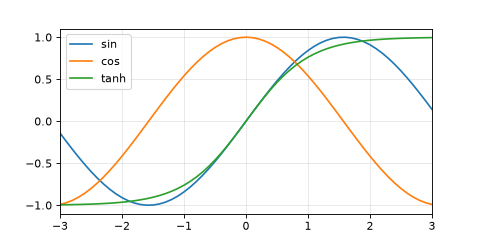

largest difference from numpy: 0.0


In [9]:
figure, axis = plt.subplots(figsize=(6, 3))
worst = 0.0
for name in ("sin", "cos", "tanh"):
    node = numpy_nodes[name]
    values = [number(node.call({"x": float(x)})) for x in GRID]
    expected = getattr(np, name)(GRID)
    worst = max(worst, float(np.max(np.abs(np.array(values) - expected))))
    axis.plot(GRID, values, label=name)
axis.legend()
axis.set_xlim(-WIDE / 2, WIDE / 2)
axis.grid(alpha=0.3)
buffer = io.BytesIO()
figure.savefig(buffer, format="png", dpi=PICTURE_DPI)
plt.close(figure)
ipython_display.display(ipython_display.Image(data=buffer.getvalue()))
print("largest difference from numpy:", worst)
assert worst < TOLERANCE

## Conclusions

Run on 2026-10-23 with numpy 2.5.4.

- `nodes_from_ufuncs(np)` made 85 nodes and skipped 5, each with a reason.
- `sin`, `cos` and `tanh` called through the node's `call` on 61 numbers gave exactly what numpy gives: the largest difference was 0.0.
- That is three of the 85 nodes, so it shows the path works, not that every ufunc node matches numpy. A wider sweep would be a guess at this point.

## What comes out

A result is a plain `float`, `int` or `bool`, never a numpy scalar. Dividing by zero gives `inf` and the log of a negative number gives `nan`, as numpy does, without a warning. A node with two outputs returns both through one result. A number on a float port is made a float before the call, so a whole number cannot overflow in an integer loop.

In [10]:
app = App(numpy_scan.nodes)
modf = app.add_node(numpy_nodes["modf"], x=0.0, y=0.0)
hypot = app.add_node(numpy_nodes["hypot"], x=300.0, y=0.0)
for node, port, value in (
    (modf, "x", 2.5),
    (hypot, "x1", 3.0),
    (hypot, "x2", 4.0),
):
    app.apply(SetValue(node=node, port=port, value=value))
result = app.run()
print(result)
assert result[modf] == {"out1": 0.5, "out2": 2.0}
assert result[hypot] == {"out": 5.0}
assert type(result[hypot]["out"]) is float

{'n1': {'out1': 0.5, 'out2': 2.0}, 'n2': {'out': 5.0}}


In [11]:
divide = numpy_nodes["divide"].call({"x1": 1.0, "x2": 0.0})
log = number(numpy_nodes["log"].call({"x": -1.0}))
isnan = numpy_nodes["isnan"].call({"x": float("nan")})
big = 2**62
total = number(numpy_nodes["add"].call({"x1": big, "x2": big}))
print(divide, log, isnan, total)
assert divide == float("inf")
assert math.isnan(log)
assert isnan is True
assert math.isclose(total, float(big) * 2)

inf nan True 9.223372036854776e+18
